# CRISP-DM phase 2 : Data Understanding, D10 (Diabetes Dataset 2019, Tigga)

Responsable : Omar (diabète)

**À surveiller :** 952 réponses à un questionnaire de dépistage du diabète de type 2. Énormément de doublons (622 sur 952 lignes). Fautes de frappe ('o' pour 'no', 'Low'/'low'), espaces et NaNs à nettoyer dans transform.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.datasets import load, REGISTRY

DS = 'D10'
df, target = load(DS)   # vérifie aussi la taille face au tableau 2 de l'article
REGISTRY[DS]['name'], df.shape

[D10] lignes=952 pos=267 neg=685 | article: lignes=952 pos=267 neg=685 -> OK


('Diabetes Dataset 2019', (952, 18))

## 1. Structure et dictionnaire des variables
Compléter le tableau dans le rapport : nom, signification médicale, type, unité.

In [2]:
df.head()

,Age,Gender,Family_Diabetes,highBP,PhysicallyActive,BMI,Smoking,Alcohol,Sleep,SoundSleep,RegularMedicine,JunkFood,Stress,BPLevel,Pregancies,Pdiabetes,UriationFreq,Diabetic
0,50-59,Male,no,yes,one hr or more,39.0,no,no,8,6,no,occasionally,sometimes,high,0.0,no,not much,0
1,50-59,Male,no,yes,less than half an hr,28.0,no,no,8,6,yes,very often,sometimes,normal,0.0,no,not much,0
2,40-49,Male,no,no,one hr or more,24.0,no,no,6,6,no,occasionally,sometimes,normal,0.0,no,not much,0
3,50-59,Male,no,no,one hr or more,23.0,no,no,8,6,no,occasionally,sometimes,normal,0.0,no,not much,0
4,40-49,Male,no,no,less than half an hr,27.0,no,no,8,8,no,occasionally,sometimes,normal,0.0,no,not much,0


In [3]:
pd.DataFrame({'dtype': df.dtypes, 'n_unique': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

,dtype,n_unique,min,max
Age,str,4,NaN,NaN
Alcohol,str,2,NaN,NaN
BMI,float64,26,15.0,45.0
BPLevel,str,3,NaN,NaN
Diabetic,int64,2,0.0,1.0
Family_Diabetes,str,2,NaN,NaN
Gender,str,2,NaN,NaN
JunkFood,str,4,NaN,NaN
Pdiabetes,str,2,NaN,NaN
PhysicallyActive,str,4,NaN,NaN


## 2. Variable cible

Diabetic
0    685
1    267
Name: count, dtype: int64 
 Diabetic
0    0.72
1    0.28
Name: count, dtype: float64


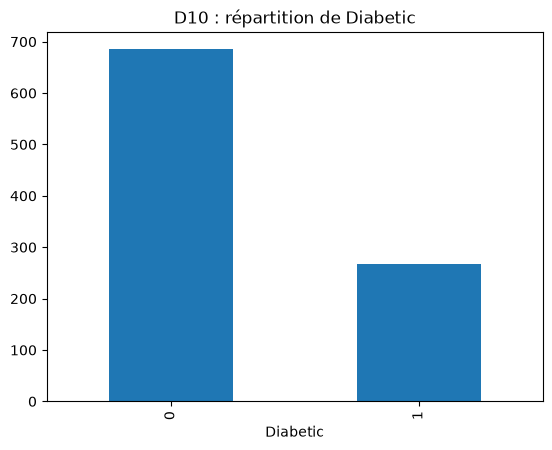

In [4]:
counts = df[target].value_counts().sort_index()
print(counts, '\n', (counts / len(df)).round(3))
counts.plot.bar(title=f'{DS} : répartition de {target}')
plt.show()

## 3. Valeurs manquantes (vraies et codées)

In [5]:
print('Valeurs nulles explicites :')
print(df.isna().sum()[df.isna().sum() > 0])

# Zéros médicalement impossibles (spécifique au diabète)
for c in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    if c in df:
        z = (df[c] == 0).sum()
        print(f'{c} = 0 : {z} ({z / len(df) * 100:.1f}%)')

Valeurs nulles explicites :
BMI    4
dtype: int64
BMI = 0 : 0 (0.0%)


## 4. Doublons
L'article ne dit pas les avoir supprimés : on les **garde** pour reproduire ses résultats, puis on relance avec `--dedup` pour mesurer leur effet.

In [6]:
n_dup = df.duplicated().sum()
print(f'{n_dup} doublons sur {len(df)} lignes ({n_dup / len(df) * 100:.1f}%) -> {len(df) - n_dup} lignes uniques')
print('Répartition de la cible après déduplication :')
print(df.drop_duplicates()[target].value_counts())

675 doublons sur 952 lignes (70.9%) -> 277 lignes uniques
Répartition de la cible après déduplication :
Diabetic
0    187
1     90
Name: count, dtype: int64


## 5. Statistiques descriptives et distributions

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
BMI,948.0,25.76,5.40,15.0,22.0,25.0,29.0,45.0
Sleep,952.0,6.95,1.27,4.0,6.0,7.0,8.0,11.0
SoundSleep,952.0,5.50,1.87,0.0,4.0,6.0,7.0,11.0
Pregancies,952.0,0.37,0.89,0.0,0.0,0.0,0.0,4.0
Diabetic,952.0,0.28,0.45,0.0,0.0,0.0,1.0,1.0


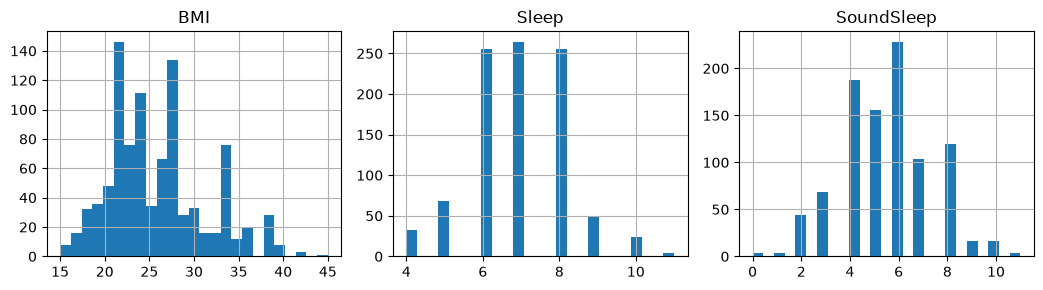

In [8]:
num = [c for c in df.columns if c != target and pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() > 5]
if num:
    df[num].hist(bins=25, figsize=(14, 3 * ((len(num) + 3) // 4)), layout=(-1, 4))
    plt.tight_layout()
    plt.show()
else:
    print('Pas de variables numériques continues (> 5 modalités)')

## 6. Valeurs aberrantes (méthode IQR)
Interpréter médicalement : erreur de saisie ou patient réellement extrême ?

In [9]:
if num:
    q1, q3 = df[num].quantile(0.25), df[num].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[num] < q1 - 1.5 * iqr) | (df[num] > q3 + 1.5 * iqr)).sum().sort_values(ascending=False)
    print(outliers[outliers > 0])
else:
    print('Aucune variable numérique continue')

BMI    8
dtype: int64


## 7. Variables selon la classe

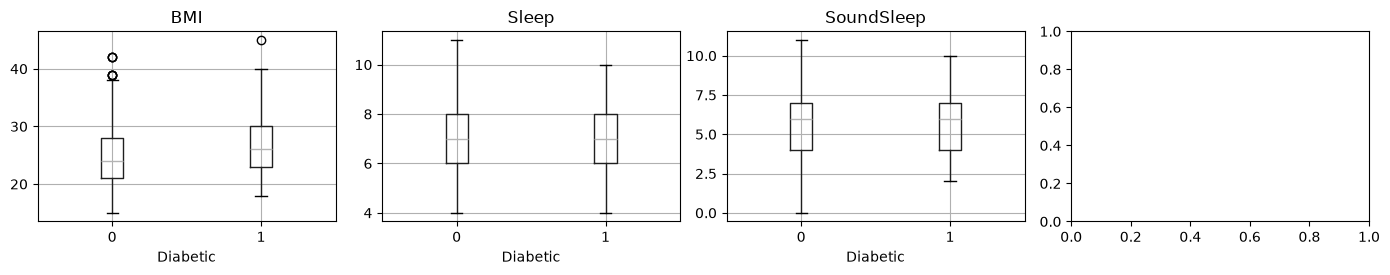

In [10]:
if num:
    fig, axes = plt.subplots((len(num) + 3) // 4, 4, figsize=(14, 3 * ((len(num) + 3) // 4)))
    for ax, c in zip(axes.flat, num):
        df.boxplot(column=c, by=target, ax=ax)
    plt.suptitle('')
    plt.tight_layout()
    plt.show()

In [11]:
cat = [c for c in df.columns if c != target and (df[c].nunique() <= 5 or not pd.api.types.is_numeric_dtype(df[c]))]
for c in cat[:10]:
    print(f'=== {c} vs {target} ===')
    print(pd.crosstab(df[c], df[target], normalize='index').round(2), '\n')

=== Age vs Diabetic ===
Diabetic         0     1
Age                     
40-49         0.70  0.30
50-59         0.54  0.46
60 or older   0.22  0.78
less than 40  0.93  0.07 

=== Gender vs Diabetic ===
Diabetic     0     1
Gender              
Female    0.70  0.30
Male      0.73  0.27 

=== Family_Diabetes vs Diabetic ===
Diabetic            0     1
Family_Diabetes            
no               0.83  0.17
yes              0.60  0.40 

=== highBP vs Diabetic ===
Diabetic     0     1
highBP              
no        0.81  0.19
yes       0.42  0.58 

=== PhysicallyActive vs Diabetic ===
Diabetic                 0     1
PhysicallyActive                
less than half an hr  0.75  0.25
more than half an hr  0.76  0.24
none                  0.58  0.42
one hr or more        0.70  0.30 

=== Smoking vs Diabetic ===
Diabetic     0     1
Smoking             
no        0.72  0.28
yes       0.73  0.27 

=== Alcohol vs Diabetic ===
Diabetic     0     1
Alcohol             
no        0.73  0.27
yes   

## 8. Corrélations

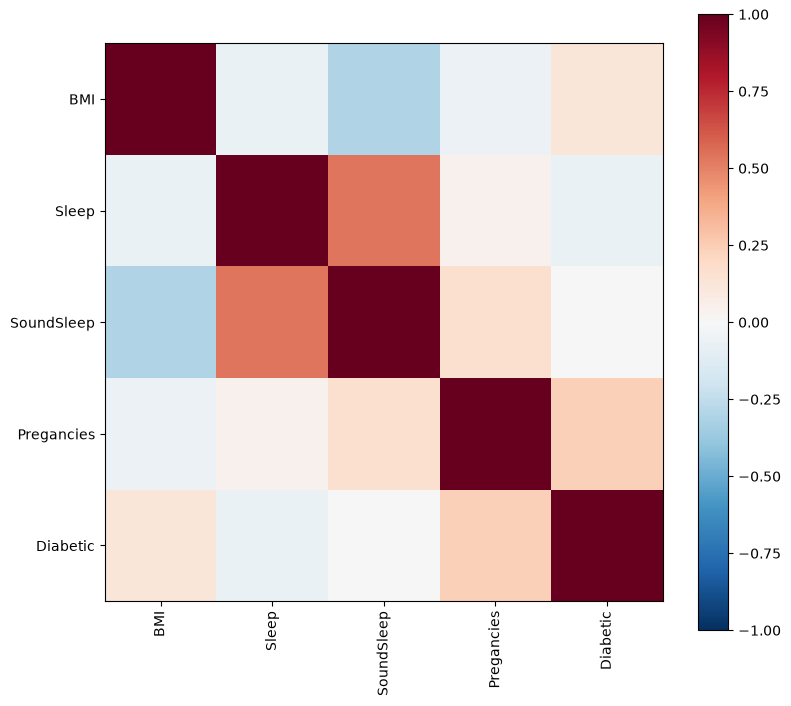

Corrélations avec la cible :
Pregancies    0.237
BMI           0.125
Sleep        -0.065
SoundSleep    0.002
Name: Diabetic, dtype: float64


In [12]:
corr = df.select_dtypes('number').corr()
if len(corr) > 1:
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)), corr.columns)
    plt.colorbar(im)
    plt.show()
    if target in corr.columns:
        print('Corrélations avec la cible :')
        print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3))

## 9. Conclusions pour la préparation (phase 3)

- Variables à encoder : nombreuses variables ordinales/catégorielles sous forme de texte ('Age', 'Gender', 'PhysicallyActive', 'BPLevel', etc.).
- Valeurs manquantes / codées à traiter : 'RegularMedicine' contenait 'o' au lieu de 'no'. 'BPLevel' contenait des variantes de casse ('Low'/'low'). 'Diabetic' contenait 1 valeur manquante (imputée pour obtenir les 267 positifs de l'article). 'Pregancies' contient des NaNs chez les hommes (remplacés par 0).
- Doublons : 622 doublons sur 952 lignes (65.3% !). Analyse critique indispensable avec `--dedup`.
- Normalisation : StandardScaler dans le Pipeline.